# 05 · Định giá (module phụ)

XGBoost dự đoán log giá/m² của tin bán từ đặc trưng cấu trúc (`tabular`), có thêm vector mô tả nén PCA (`full`); so với baseline
trung vị phường. Định giá là tool `valuate()` cho router (tuyến `valuation`) và endpoint `/api/valuate`.

**Lệnh sinh:** `python scripts/vre_pipeline.py price --variant tabular|full` → `results/valuation_metrics.json`, `models/valuation/`.

In [1]:
%run ./00_setup.ipynb

Chế độ: **live khi có dịch vụ/model, không thì đọc cache**; kết quả đọc từ `results/` dưới `VRE_DATA_ROOT`.

,giá trị
embedding,intfloat/multilingual-e5-large
collection,vre_chunks_e5_large
alias,vre_chunks
chunk_size,400
chunk_overlap,100
header_max_tokens,96
top_k,5
rrf_k,60
llm_provider,groq
llm_model,openai/gpt-oss-120b


### P5-01 · Chia theo thời gian: train `2025-06`–`2026-01`, test `2026-02`–`2026-03`
**ẨN**

Mục tiêu: chia train/test theo thời gian (tháng cuối làm test) thay vì ngẫu nhiên, vì tin gần trùng đăng lại nhiều lần sẽ rò rỉ giữa
hai tập nếu chia ngẫu nhiên, làm sai số trông thấp giả. Cell kiểm model có trên máy không (CI không có `models/`).

In [2]:
# P5-01 · ẨN
vm = load("valuation_metrics.json")
md("Model tabular: " + ("có trên máy." if available("models") else "không có trên máy này, cell LIVE đọc cache cell."))
if vm is not None:
    display(pd.Series({**vm["split"], **vm["rent_model"]}, name="giá trị").to_frame())

Model tabular: có trên máy.

,giá trị
train_months,"[2025-06, 2026-01]"
test_months,"[2026-02, 2026-03]"
trained,False
n_rent,253
reason,n_rent=253 < rent_min_rows=20000


### P5-02 · `tabular` dùng 24 đặc trưng, `full` thêm 32 thành phần PCA của mô tả
**CACHE**

Mục tiêu: đặc trưng. Biến số (diện tích, số phòng, tầng, mặt tiền, đường), biến hạng mục (loại, hướng), tiện ích dạng cờ, và target
encoding của tỉnh/quận/phường/đường/dự án (trung bình log giá tính out-of-fold để không rò nhãn). `full` thêm các thành phần PCA của
vector e5 trung bình theo tin — thông tin trong mô tả mà cột cấu trúc không có.

In [3]:
# P5-02 · CACHE
if vm is None:
    missing("`results/valuation_metrics.json`", "python scripts/vre_pipeline.py price --variant tabular")
else:
    feats = [f["feature"] for f in vm["variants"]["tabular"]["shap_top"]]
    groups = {"target encoding": [f for f in feats if f.startswith("te_")], "tiện ích": [f for f in feats if f.startswith("am_")],
              "còn lại": [f for f in feats if not f.startswith(("te_", "am_"))]}
    display(pd.Series({k: ", ".join(v) for k, v in groups.items()}, name="đặc trưng").to_frame())

,đặc trưng
target encoding,"te_district_key, te_ward_key, te_province, te_street_key, te_project_key"
tiện ích,"am_mat_tien, am_thang_may, am_hem_xe_hoi, am_so_hong, am_gan_truong, am_ho_boi, am_noi..."
còn lại,"property_type, area_m2, month_idx, bedrooms, bathrooms, house_direction, frontage_m, f..."


### P5-03 · `full` giảm MAPE xuống 19,1% (tabular 24,0%, baseline trung vị phường 46,0%)
**CACHE**

Mục tiêu: so ba biến thể trên cùng tập test: MAE (triệu/m²), MAPE và R². Baseline trung vị phường là cách định giá "theo khu vực"
mà người mua thường làm; model phải thắng nó mới có ích. Lưu ý: `full` chỉ dùng cho tin thật có mô tả; BĐS giả định nhập tay không
có vector mô tả nên API định giá bằng `tabular`.

In [4]:
# P5-03 · CACHE
if vm is not None:
    cmp = pd.DataFrame({k: {m: v[m] for m in ("n_train", "n_test", "mae_mil_m2", "mape", "r2", "train_seconds")}
                        for k, v in vm["variants"].items() if v is not None}).T
    display(cmp)

,n_train,n_test,mae_mil_m2,mape,r2,train_seconds
tabular,1865193.0,395910.0,32.624495,0.240247,0.727003,3436.9
full,1865193.0,395910.0,24.049848,0.190938,0.844781,1758.0
baseline_ward_median,1865193.0,395910.0,50.613928,0.460424,0.476394,0.0


### P5-04 · Sai số lớn nhất ở loại 'Đất' (MAPE tabular 33,0%)
**CACHE**

Mục tiêu: sai số theo loại bất động sản. Đất có MAPE cao vì giá phụ thuộc pháp lý, quy hoạch, mặt tiền — thông tin thường chỉ có
trong mô tả; căn hộ đồng nhất hơn nên dễ đoán hơn. Cách đọc: so cột `full` với `tabular` để thấy mô tả giúp loại nào nhiều nhất.

,tabular,full,baseline_ward_median
property_type,,,
Biệt thự/Nhà liền kề,0.200265,0.175829,0.369527
Căn hộ chung cư,0.161572,0.126173,0.666149
Nhà,0.243191,0.184916,0.324393
Shophouse,0.250854,0.224080,0.456840
Đất,0.330025,0.272810,0.538061


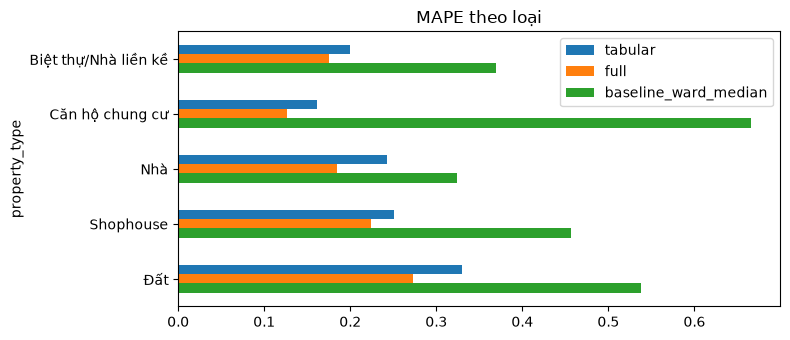

In [5]:
# P5-04 · CACHE
if vm is not None:
    parts = [pd.DataFrame(v["by_property_type"]).set_index("property_type")["mape"].rename(k)
             for k, v in vm["variants"].items() if v is not None and v["by_property_type"]]
    by_type = pd.concat(parts, axis=1)
    display(by_type)
    by_type.plot.barh(figsize=(8, 3.5), title="MAPE theo loại").invert_yaxis()
    plt.tight_layout()
    plt.show()

### P5-05 · Trong mười tỉnh nhiều tin nhất, Hưng Yên dự đoán tốt nhất (MAPE tabular 14,8%)
**CACHE**

Mục tiêu: sai số theo tỉnh trong nhóm nhiều tin nhất. Tỉnh có thị trường đồng đều hoặc nhiều tin huấn luyện dự đoán tốt hơn; thành
phố lớn có chênh lệch giá rất lớn giữa các phố nên sai số tuyệt đối cao.

In [6]:
# P5-05 · CACHE
if vm is not None:
    parts = [pd.DataFrame(v["by_province_top10"]).set_index("province")["mape"].rename(k)
             for k, v in vm["variants"].items() if v is not None and v["by_province_top10"]]
    display(pd.concat(parts, axis=1))

,tabular,full,baseline_ward_median
province,,,
Hồ Chí Minh,0.230105,0.176578,0.411671
Hà Nội,0.228730,0.160687,0.530166
Đà Nẵng,0.191917,0.165427,0.293008
Bình Dương,0.178595,0.233025,0.321064
Khánh Hòa,0.261045,0.226041,0.490071
Hải Phòng,0.226208,0.196465,0.448184
Đồng Nai,0.302607,0.263861,0.584233
Hưng Yên,0.147875,0.123150,0.389115
Long An,0.362701,0.294079,0.561695


### P5-06 · Theo SHAP, `property_type` và `te_district_key` đóng góp nhiều nhất
**CACHE**

Mục tiêu: SHAP phân rã từng dự đoán thành đóng góp của từng đặc trưng (trên thang log giá); trung bình trị tuyệt đối cho tầm quan
trọng toàn cục. Cách đọc: vị trí (target encoding quận/phường) và loại hình chiếm phần lớn; ở `full`, thành phần PCA của mô tả chen vào
nhóm đầu — mô tả mang thông tin giá thật.

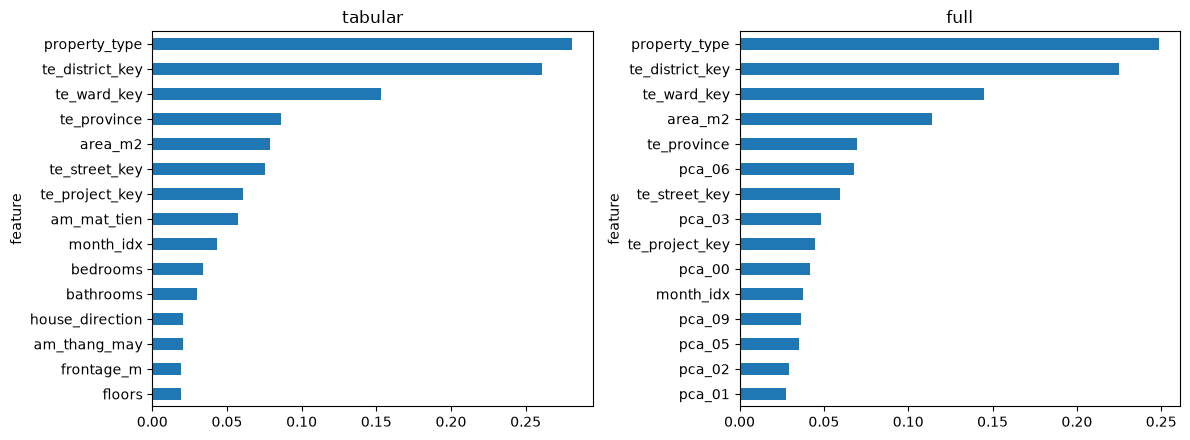

In [7]:
# P5-06 · CACHE
if vm is not None:
    shap = {k: v for k, v in vm["variants"].items() if v is not None and v["shap_top"]}
    fig, axes = plt.subplots(1, len(shap), figsize=(6 * len(shap), 4.5), squeeze=False)
    for ax, (k, v) in zip(axes[0], shap.items(), strict=True):
        pd.DataFrame(v["shap_top"]).head(15).set_index("feature")["mean_abs_contribution"].plot.barh(ax=ax, title=k)
        ax.invert_yaxis()
    fig.tight_layout()
    plt.show()

### P5-07 · Căn hộ giả định được định giá 50,2 triệu/m², giá chào nằm ở mức `above_market`
**LIVE**

Mục tiêu: một lần `valuate()` thật cho căn hộ giả định có giá chào. Kết quả gồm giá/m² và giá tổng dự đoán, khoảng giá (từ phân vị sai
số trên tập test theo loại), trung vị phường để đối chiếu, phán quyết so với giá chào và đóng góp SHAP của chính căn này.

In [8]:
# P5-07 · LIVE
PAYLOAD = {"property_type": "Căn hộ chung cư", "province": "Hồ Chí Minh", "district": "Quận 7", "area_m2": 70, "bedrooms": 2,
           "bathrooms": 2, "asking_price_vnd": 4.5e9}


def compute():
    from vre.valuation.predict import valuate

    return {"input": PAYLOAD, "result": valuate(PAYLOAD, variant="tabular")}


d = live("P5-07", compute, needs=("models", "data"))
if d:
    r = d["result"]
    md(f"Dự đoán {dec(r['predicted_price_m2_mil'], 1)} triệu/m² ⇒ {dec(r['predicted_price_vnd'] / 1e9, 2)} tỷ "
       f"(khoảng {dec(r['interval_price_vnd']['low'] / 1e9, 2)} – {dec(r['interval_price_vnd']['high'] / 1e9, 2)} tỷ); "
       f"giá chào {dec(PAYLOAD['asking_price_vnd'] / 1e9, 2)} tỷ ⇒ `{r['verdict']}`; model `{r['model']['variant']}`.")
    table(r["shap"])

*Chạy live, đã ghi cache cell.*

Dự đoán 50,2 triệu/m² ⇒ 3,51 tỷ (khoảng 2,99 – 4,20 tỷ); giá chào 4,50 tỷ ⇒ `above_market`; model `tabular`.

,feature,value,contribution_log
0,property_type,Căn hộ chung cư,-0.311555
1,te_district_key,Hồ Chí Minh|Quận 7,0.162152
2,te_project_key,None,-0.092769
3,month_idx,9.0,0.054572
4,te_ward_key,None,-0.049099
5,bathrooms,2.0,-0.046540
6,bedrooms,2.0,-0.039957
7,am_mat_tien,0.0,-0.038498


### P5-08 · Không huấn luyện model thuê: chỉ có 253 tin thuê
**CACHE**

Mục tiêu: phạm vi của module. Dataset gần như toàn tin bán; số tin thuê dưới ngưỡng tối thiểu nên không huấn luyện model thuê, và
`/api/valuate` trả lỗi rõ cho `deal_type = rent` thay vì đoán. Giá là giá chào do người đăng nhập, không phải giá giao dịch.

In [9]:
# P5-08 · CACHE
if vm is not None:
    display(pd.Series(vm["rent_model"], name="rent_model").to_frame())

,rent_model
trained,False
n_rent,253
reason,n_rent=253 < rent_min_rows=20000
